# RF Intrusion CNN v5 — Google Colab Training and Evaluation

Train and evaluate CNN v5 on a Colab GPU. The first code cell downloads the spectrogram dataset with `kagglehub`, then the notebook rebuilds the project's 40/10/10/40 split. The Keras artifact is written under `/content/models/tensorflow_training`.

v4 remains the best overall model (test accuracy 0.8875, macro F1 0.8865). v5 targets its weak class: **Machine recall is 0.645**, and 118 of the 142 misses are predicted Benign.

## Before you run

1. In Colab, choose **Runtime → Change runtime type → A100 GPU**.
2. On the [dataset page](https://www.kaggle.com/datasets/hector484/unified-multi-class-rf-intrusion-dataset), join or accept the rules if Kaggle asks.
3. Run the cells from the top. If a Kaggle sign-in window opens, sign in and allow access.
4. Run the last cell before the session ends. Colab deletes `/content` when the runtime stops.


## 1. Download the dataset

This is the download snippet from the Kaggle dataset page.


In [1]:
%pip install -q kagglehub pandas scikit-learn matplotlib


In [2]:
import kagglehub
from pathlib import Path

# Download latest version
path = kagglehub.dataset_download("hector484/unified-multi-class-rf-intrusion-dataset")

print("Path to dataset files:", path)

root = Path(path)
candidates = [item for item in [root, root / "unified_dataset"] if (item / "train").is_dir()]
candidates += [item for item in root.rglob("unified_dataset") if (item / "train").is_dir()]
if not candidates:
    raise FileNotFoundError(f"unified_dataset/train was not inside {path}")
dataset_root = candidates[0]
Path("/content/kaggle_dataset_root.txt").write_text(str(dataset_root))
print("Dataset ready:", dataset_root)


100%|██████████| 324M/324M [00:02<00:00, 144MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/hector484/unified-multi-class-rf-intrusion-dataset/versions/1
Dataset ready: /root/.cache/kagglehub/datasets/hector484/unified-multi-class-rf-intrusion-dataset/versions/1/unified_dataset


In [3]:
import json
import random
import urllib.request
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)

SEED = 42
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
EXPECTED_CLASSES = ["Benign", "Broadband_Jam", "Human", "Machine", "Narrowband_Jam", "Wildlife"]
# Classes are balanced. 2.0 raised Machine recall to 0.965 and dropped Benign recall from 0.853 to 0.323.
MACHINE_LOSS_WEIGHT = 1.
METADATA_URL = (
    "https://raw.githubusercontent.com/Mosizamani/aai-540-final-project-group6/"
    "main/rf_intrusion_assignment_split_metadata.csv"
)

WORKDIR = Path("/content")
DATA_ROOT = WORKDIR / "rf_assignment_split"
ARTIFACT_DIR = WORKDIR / "models" / "tensorflow_training"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

gpus = tf.config.list_physical_devices("GPU")
print("TensorFlow:", tf.__version__)
print("GPUs:", gpus)
if not gpus:
    raise RuntimeError("No GPU detected. Use Runtime → Change runtime type → A100 GPU, then rerun from the top.")
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as exc:
        print("GPU memory growth left at the Colab default:", exc)


TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Rebuild the assignment split

Kaggle's original folders are `train`, `val`, and `test`. The project mixes those images into a stratified 40/10/10/40 split: 9,600 train, 2,400 validation, 2,400 test, and 9,600 production. The class and filename assignments are the committed metadata file, so this test set is the same one used to score v4. Images are linked into `/content/rf_assignment_split` rather than copied.


In [4]:
dataset_root = Path(Path("/content/kaggle_dataset_root.txt").read_text().strip())
if not (dataset_root / "train").is_dir():
    raise FileNotFoundError("Run the kagglehub download cell above before this cell.")
print("Dataset root:", dataset_root)

source_index = {}
for original_split in ("train", "val", "test"):
    split_path = dataset_root / original_split
    assert split_path.is_dir(), split_path
    for class_dir in split_path.iterdir():
        if not class_dir.is_dir():
            continue
        for image_path in class_dir.glob("*.png"):
            source_index[(class_dir.name, image_path.name)] = image_path
print("Downloaded images:", len(source_index))

metadata_path = WORKDIR / "rf_intrusion_assignment_split_metadata.csv"
urllib.request.urlretrieve(METADATA_URL, metadata_path)
assignments = pd.read_csv(metadata_path)
assert list(assignments.columns) == [
    "image_path", "filename", "class_label", "original_split", "assignment_split"
]
assert len(assignments) == 24000

if DATA_ROOT.exists():
    import shutil
    shutil.rmtree(DATA_ROOT)

missing = 0
for row in assignments.itertuples(index=False):
    source = source_index.get((row.class_label, row.filename))
    if source is None:
        missing += 1
        continue
    target = DATA_ROOT / row.assignment_split / row.class_label / row.filename
    target.parent.mkdir(parents=True, exist_ok=True)
    target.symlink_to(source)
if missing:
    raise FileNotFoundError(f"{missing} metadata rows did not match a downloaded image.")

for split_name, expected in (("train", 9600), ("validation", 2400), ("test", 2400), ("production", 9600)):
    count = sum(1 for _ in (DATA_ROOT / split_name).glob("*/*.png"))
    print(f"{split_name}: {count}")
    assert count == expected, (split_name, count, expected)
print("Assignment split ready:", DATA_ROOT)


Dataset root: /root/.cache/kagglehub/datasets/hector484/unified-multi-class-rf-intrusion-dataset/versions/1/unified_dataset
Downloaded images: 24000
train: 9600
validation: 2400
test: 2400
production: 9600
Assignment split ready: /content/rf_assignment_split


In [5]:
train_dir = DATA_ROOT / "train"
validation_dir = DATA_ROOT / "validation"
test_dir = DATA_ROOT / "test"
class_names = sorted(path.name for path in train_dir.iterdir() if path.is_dir())
assert class_names == EXPECTED_CLASSES, class_names

def make_dataset(path, shuffle):
    return tf.keras.utils.image_dataset_from_directory(
        path,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        label_mode="categorical",
        color_mode="rgb",
        shuffle=shuffle,
        seed=SEED if shuffle else None,
        follow_links=True,
    ).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_dir, True)
validation_ds = make_dataset(validation_dir, False)
test_ds = make_dataset(test_dir, False)
print("Classes:", class_names)


Found 9600 files belonging to 6 classes.
Found 2400 files belonging to 6 classes.
Found 2400 files belonging to 6 classes.
Classes: ['Benign', 'Broadband_Jam', 'Human', 'Machine', 'Narrowband_Jam', 'Wildlife']


## 3. v4 baseline and evaluation helper

These figures are the saved v4 test result. Machine recall is 258/400. Of the 142 misses, 118 were predicted Benign, 22 Wildlife, and 2 Human. v4 also labeled 59 true Benign images as Machine.


In [6]:
# Rows are true labels and columns are predicted labels, in EXPECTED_CLASSES order.
V4_CONFUSION = np.array([
    [341, 0, 0, 59, 0, 0],
    [1, 399, 0, 0, 0, 0],
    [0, 0, 375, 4, 0, 21],
    [118, 0, 2, 258, 0, 22],
    [0, 2, 0, 0, 398, 0],
    [0, 0, 18, 23, 0, 359],
])

def metrics_from_confusion(matrix):
    report = {}
    f1_scores = []
    for index, name in enumerate(EXPECTED_CLASSES):
        true_positive = matrix[index, index]
        support = matrix[index].sum()
        predicted = matrix[:, index].sum()
        precision = true_positive / predicted
        recall = true_positive / support
        f1 = 2 * precision * recall / (precision + recall)
        report[name] = {
            "precision": float(precision),
            "recall": float(recall),
            "f1-score": float(f1),
            "support": int(support),
        }
        f1_scores.append(f1)
    return {
        "class_names": EXPECTED_CLASSES,
        "evaluation": {
            "test_accuracy": float(np.trace(matrix) / matrix.sum()),
            "macro_f1": float(np.mean(f1_scores)),
            "classification_report": report,
            "confusion_matrix": matrix.tolist(),
        },
    }

v4_metrics = metrics_from_confusion(V4_CONFUSION)
V4_ACCURACY = v4_metrics["evaluation"]["test_accuracy"]
V4_MACRO_F1 = v4_metrics["evaluation"]["macro_f1"]
V4_MACHINE_RECALL = v4_metrics["evaluation"]["classification_report"]["Machine"]["recall"]
print(
    f"CNN v4 baseline — accuracy: {V4_ACCURACY:.4f}, macro F1: {V4_MACRO_F1:.4f}, "
    f"Machine recall: {V4_MACHINE_RECALL:.4f}"
)

def evaluate_and_save(model, version, history):
    probabilities = model.predict(test_ds, verbose=1)
    y_pred = np.argmax(probabilities, axis=1)
    y_true = np.concatenate([np.argmax(labels.numpy(), axis=1) for _, labels in test_ds])
    macro_precision, macro_recall, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    metrics = {
        "model_version": version,
        "created_utc": datetime.now(timezone.utc).isoformat(),
        "input_shape": [128, 128, 3],
        "class_names": class_names,
        "machine_loss_weight": MACHINE_LOSS_WEIGHT,
        "evaluation": {
            "test_accuracy": float(accuracy_score(y_true, y_pred)),
            "macro_precision": float(macro_precision),
            "macro_recall": float(macro_recall),
            "macro_f1": float(macro_f1),
            "classification_report": classification_report(
                y_true, y_pred, target_names=class_names, output_dict=True, zero_division=0
            ),
            "confusion_matrix": confusion_matrix(y_true, y_pred).tolist(),
        },
        "history": {key: [float(value) for value in values] for key, values in history.history.items()},
    }
    model_path = ARTIFACT_DIR / f"rf_intrusion_cnn_{version}.keras"
    metrics_path = ARTIFACT_DIR / f"rf_intrusion_cnn_{version}_metrics.json"
    model.save(model_path)
    metrics_path.write_text(json.dumps(metrics, indent=2))
    matrix = np.array(metrics["evaluation"]["confusion_matrix"])
    fig, ax = plt.subplots(figsize=(10, 8))
    ConfusionMatrixDisplay(matrix, display_labels=class_names).plot(ax=ax, cmap="Blues", values_format="d")
    ax.set_title(f"CNN {version} — Test Confusion Matrix")
    ax.tick_params(axis="x", labelrotation=45)
    fig.tight_layout()
    fig.savefig(ARTIFACT_DIR / f"rf_intrusion_cnn_{version}_confusion_matrix.png", dpi=160)
    plt.show()
    print(f"Saved {model_path} and {metrics_path.name}")
    return metrics, model_path


CNN v4 baseline — accuracy: 0.8875, macro F1: 0.8865, Machine recall: 0.6450


## 4. CNN v5

v5 keeps the v4 convolution stack and training schedule. Two changes target the Benign ↔ Machine confusion.

1. **Pooling head.** Global average pooling is concatenated with global max pooling, so a sparse bright machine trace is not averaged into a Benign-looking vector.
2. **Loss weight.** Machine has loss weight `MACHINE_LOSS_WEIGHT` (1.25). The other five classes stay at 1.0. A weight of 2.0 made the model call most ambiguous Benign images Machine.

Training matches v4: Adam at 0.0002, up to 30 epochs, early stopping on validation loss with patience 5 and best weights restored, and `ReduceLROnPlateau` (factor 0.5, patience 2, minimum learning rate 1e-6).


In [7]:
def conv_stage(x, filters, dropout_rate=0.0):
    """v4 stage: two 3x3 convs, then max pool and optional dropout."""
    for _ in range(2):
        x = tf.keras.layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.ReLU()(x)
    x = tf.keras.layers.MaxPooling2D()(x)
    if dropout_rate:
        x = tf.keras.layers.Dropout(dropout_rate)(x)
    return x

def weighted_categorical_crossentropy(class_weights):
    """class_weights aligns with class_names. One-hot labels select the weight."""
    weights = tf.constant(class_weights, dtype=tf.float32)

    def loss(y_true, y_pred):
        y_true = tf.cast(y_true, tf.float32)
        per_sample = tf.keras.losses.categorical_crossentropy(y_true, y_pred)
        sample_weight = tf.reduce_sum(y_true * weights, axis=-1)
        return per_sample * sample_weight

    return loss

def build_v5():
    inputs = tf.keras.Input(shape=(128, 128, 3), name="spectrogram")
    x = tf.keras.layers.Rescaling(1.0 / 255)(inputs)
    x = conv_stage(x, 32)
    x = conv_stage(x, 64, dropout_rate=0.05)
    x = conv_stage(x, 128, dropout_rate=0.08)
    x = conv_stage(x, 256, dropout_rate=0.10)
    average_pool = tf.keras.layers.GlobalAveragePooling2D()(x)
    max_pool = tf.keras.layers.GlobalMaxPooling2D()(x)
    x = tf.keras.layers.Concatenate()([average_pool, max_pool])
    x = tf.keras.layers.Dense(256, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.28)(x)
    outputs = tf.keras.layers.Dense(len(class_names), activation="softmax", name="class_probabilities")(x)
    class_weights = [MACHINE_LOSS_WEIGHT if name == "Machine" else 1.0 for name in class_names]
    model = tf.keras.Model(inputs, outputs, name="rf_intrusion_cnn_v5")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=2e-4),
        loss=weighted_categorical_crossentropy(class_weights),
        metrics=["accuracy"],
    )
    return model

v5_model = build_v5()
v5_model.summary()
print("Loss weights:", {name: MACHINE_LOSS_WEIGHT if name == "Machine" else 1.0 for name in class_names})


Model: "rf_intrusion_cnn_v5"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ spectrogram         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 128, 128,  │          0 │ spectrogram[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │        864 │ rescaling[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128, 128,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │      9,216 │ re_lu[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ re_lu_1[0][0]     │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     18,432 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │     36,864 │ re_lu_2[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ re_lu_3[0][0]     │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 32, 32,    │          0 │ max_pooling2d_1[

 Total params: 1,308,006 (4.99 MB)

 Trainable params: 1,306,086 (4.98 MB)

 Non-trainable params: 1,920 (7.50 KB)

Loss weights: {'Benign': 1.0, 'Broadband_Jam': 1.0, 'Human': 1.0, 'Machine': 1.0, 'Narrowband_Jam': 1.0, 'Wildlife': 1.0}


Epoch 1/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 32s 21ms/step - accuracy: 0.6595 - loss: 0.7970 - val_accuracy: 0.1667 - val_loss: 3.4793 - learning_rate: 2.0000e-04
Epoch 2/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.7676 - loss: 0.4865 - val_accuracy: 0.7504 - val_loss: 0.4961 - learning_rate: 2.0000e-04
Epoch 3/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.8127 - loss: 0.4010 - val_accuracy: 0.8317 - val_loss: 0.3906 - learning_rate: 2.0000e-04
Epoch 4/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.8384 - loss: 0.3451 - val_accuracy: 0.8650 - val_loss: 0.3206 - learning_rate: 2.0000e-04
Epoch 5/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.8565 - loss: 0.3084 - val_accuracy: 0.8683 - val_loss: 0.2872 - learning_rate: 2.0000e-04
Epoch 6/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.8662 - loss: 0.2837 - val_accuracy: 0.8125 - val_loss: 0.4034 - learning_rate: 2.0000e-04
Epoch 7/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - ac

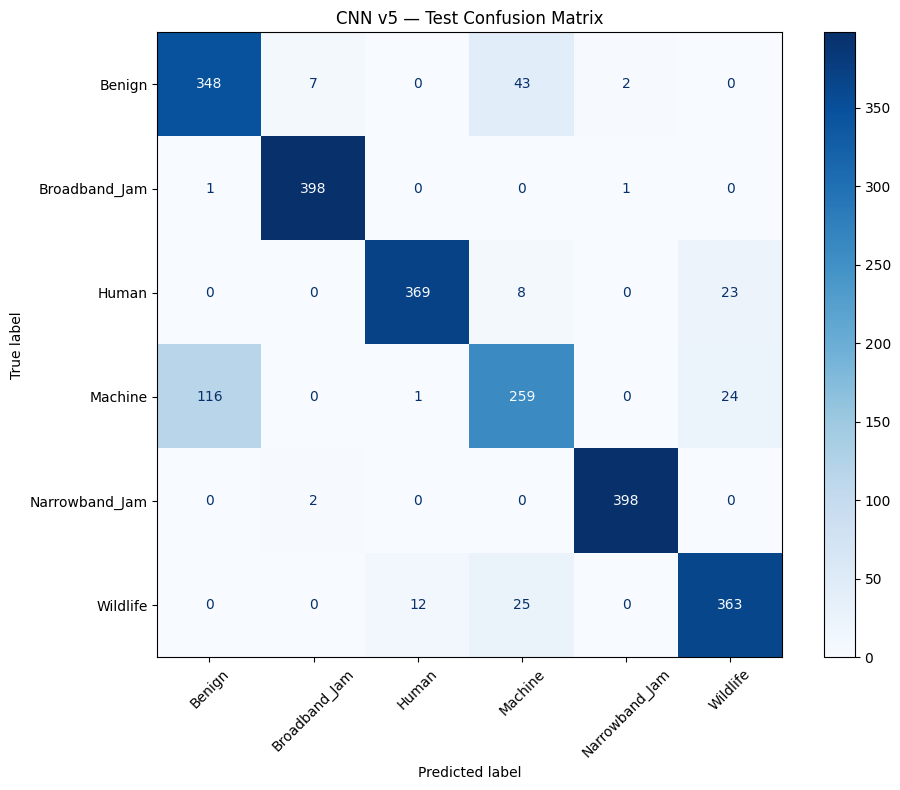

Saved /content/models/tensorflow_training/rf_intrusion_cnn_v5.keras and rf_intrusion_cnn_v5_metrics.json
CNN v5 — accuracy: 0.8896, macro F1: 0.8883, Machine recall: 0.6475


In [8]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1
    ),
]
v5_history = v5_model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=30,
    callbacks=callbacks,
    verbose=1,
)
v5_metrics, v5_path = evaluate_and_save(v5_model, "v5", v5_history)
print(
    f"CNN v5 — accuracy: {v5_metrics['evaluation']['test_accuracy']:.4f}, "
    f"macro F1: {v5_metrics['evaluation']['macro_f1']:.4f}, "
    f"Machine recall: {v5_metrics['evaluation']['classification_report']['Machine']['recall']:.4f}"
)


## 5. v4 versus v5 on Machine recall

v5 is worth keeping when Machine recall is higher than v4 and macro F1 does not fall below v4. The Benign ↔ Machine counts are the errors this version is meant to cut.


,version,accuracy,macro_f1,machine_recall,machine_precision,machine_f1,machine_as_benign,benign_as_machine,machine_correct
0,v4,0.8875,0.8865,0.6450,0.7500,0.6935,118,59,258
1,v5,0.8896,0.8883,0.6475,0.7731,0.7048,116,43,259


,v4_precision,v4_recall,v4_f1,v5_precision,v5_recall,v5_f1,recall_delta
class,,,,,,,
Benign,0.7413,0.8525,0.7930,0.7484,0.8700,0.8046,0.0175
Broadband_Jam,0.9950,0.9975,0.9963,0.9779,0.9950,0.9864,-0.0025
Human,0.9494,0.9375,0.9434,0.9660,0.9225,0.9437,-0.0150
Machine,0.7500,0.6450,0.6935,0.7731,0.6475,0.7048,0.0025
Narrowband_Jam,1.0000,0.9950,0.9975,0.9925,0.9950,0.9938,0.0000
Wildlife,0.8930,0.8975,0.8953,0.8854,0.9075,0.8963,0.0100


PASS: CNN v5 raises Machine recall and holds macro F1 at or above v4.


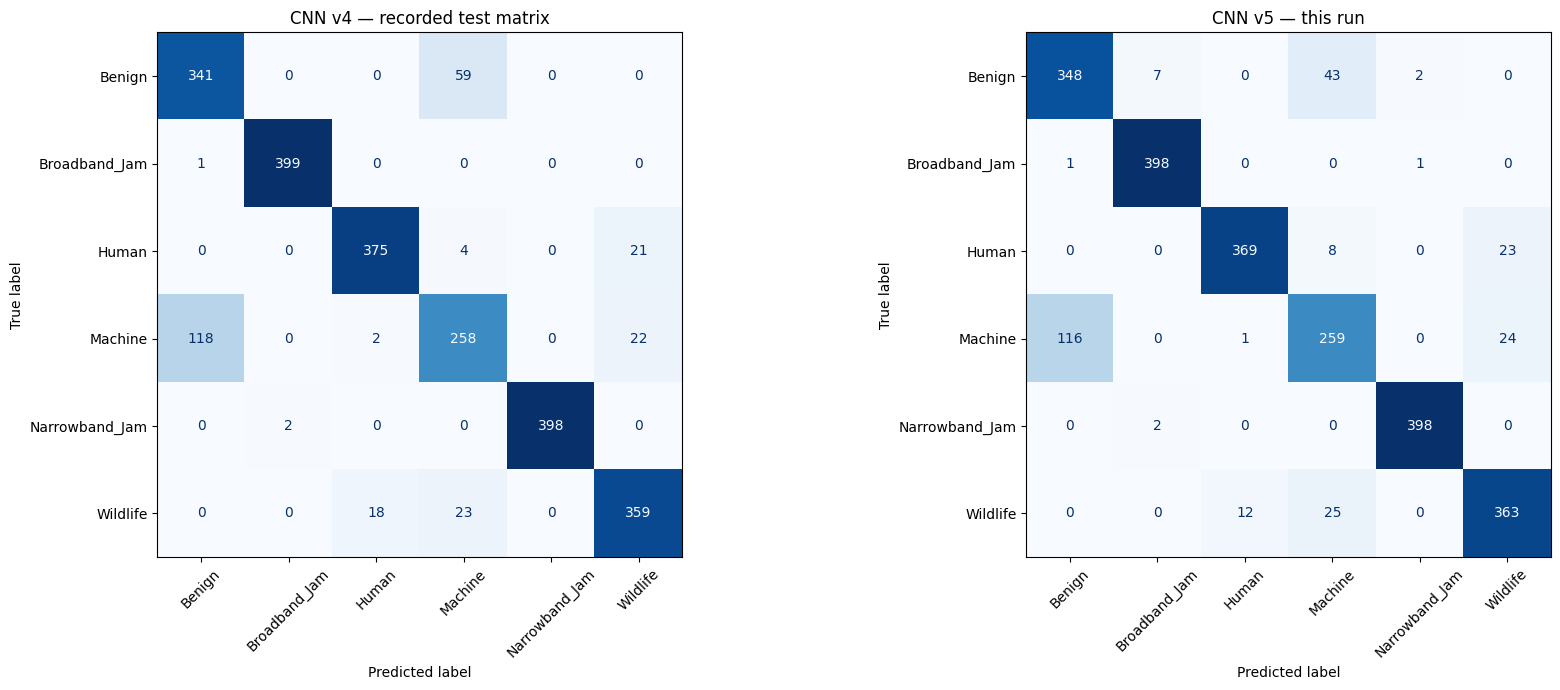

In [9]:
def swap_counts(metrics):
    labels = metrics["class_names"]
    matrix = np.array(metrics["evaluation"]["confusion_matrix"])
    benign = labels.index("Benign")
    machine = labels.index("Machine")
    return {
        "machine_as_benign": int(matrix[machine, benign]),
        "benign_as_machine": int(matrix[benign, machine]),
        "machine_correct": int(matrix[machine, machine]),
    }

v5_evaluation = v5_metrics["evaluation"]
v4_report = v4_metrics["evaluation"]["classification_report"]
v5_report = v5_evaluation["classification_report"]
v4_swaps = swap_counts(v4_metrics)
v5_swaps = swap_counts(v5_metrics)

comparison = pd.DataFrame([
    {
        "version": "v4",
        "accuracy": V4_ACCURACY,
        "macro_f1": V4_MACRO_F1,
        "machine_recall": v4_report["Machine"]["recall"],
        "machine_precision": v4_report["Machine"]["precision"],
        "machine_f1": v4_report["Machine"]["f1-score"],
        **v4_swaps,
    },
    {
        "version": "v5",
        "accuracy": v5_evaluation["test_accuracy"],
        "macro_f1": v5_evaluation["macro_f1"],
        "machine_recall": v5_report["Machine"]["recall"],
        "machine_precision": v5_report["Machine"]["precision"],
        "machine_f1": v5_report["Machine"]["f1-score"],
        **v5_swaps,
    },
])
display(comparison.style.format({
    "accuracy": "{:.4f}",
    "macro_f1": "{:.4f}",
    "machine_recall": "{:.4f}",
    "machine_precision": "{:.4f}",
    "machine_f1": "{:.4f}",
    "machine_as_benign": "{:.0f}",
    "benign_as_machine": "{:.0f}",
    "machine_correct": "{:.0f}",
}))

per_class_rows = []
for class_name in class_names:
    per_class_rows.append({
        "class": class_name,
        "v4_precision": v4_report[class_name]["precision"],
        "v4_recall": v4_report[class_name]["recall"],
        "v4_f1": v4_report[class_name]["f1-score"],
        "v5_precision": v5_report[class_name]["precision"],
        "v5_recall": v5_report[class_name]["recall"],
        "v5_f1": v5_report[class_name]["f1-score"],
        "recall_delta": v5_report[class_name]["recall"] - v4_report[class_name]["recall"],
    })
display(pd.DataFrame(per_class_rows).set_index("class").style.format("{:.4f}"))

machine_recall_up = v5_report["Machine"]["recall"] > v4_report["Machine"]["recall"]
macro_f1_held = v5_evaluation["macro_f1"] >= V4_MACRO_F1
if machine_recall_up and macro_f1_held:
    print("PASS: CNN v5 raises Machine recall and holds macro F1 at or above v4.")
elif machine_recall_up:
    print("MIXED: Machine recall is up, but macro F1 fell below v4. Keep v4 unless that trade is accepted.")
else:
    print("HOLD: CNN v5 does not raise Machine recall. Keep v4.")

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
ConfusionMatrixDisplay(V4_CONFUSION, display_labels=class_names).plot(
    ax=axes[0], cmap="Blues", values_format="d", colorbar=False
)
axes[0].set_title("CNN v4 — recorded test matrix")
axes[0].tick_params(axis="x", labelrotation=45)
ConfusionMatrixDisplay(
    np.array(v5_evaluation["confusion_matrix"]), display_labels=class_names
).plot(ax=axes[1], cmap="Blues", values_format="d", colorbar=False)
axes[1].set_title("CNN v5 — this run")
axes[1].tick_params(axis="x", labelrotation=45)
fig.tight_layout()
plt.show()


## 6. Loss-weight sweep: v5.1 through v5.6

Each run uses the same v5 architecture. The only change is the Machine loss weight, from 1.25 to 1.50 in steps of 0.05.

| Version | Machine loss weight |
|---|---:|
| v5.1 | 1.25 |
| v5.2 | 1.30 |
| v5.3 | 1.35 |
| v5.4 | 1.40 |
| v5.5 | 1.45 |
| v5.6 | 1.50 |

v4 is included in the results table with weight 1.00, because v4 does not upweight Machine. Run this after the data and `build_v5` cells. It trains six models. On an A100 that is about 5 to 8 minutes.



===== v5.1: Machine loss weight 1.25 =====
Epoch 1/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 18s 19ms/step - accuracy: 0.6576 - loss: 0.8252 - val_accuracy: 0.1667 - val_loss: 4.0284 - learning_rate: 2.0000e-04
Epoch 2/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.7597 - loss: 0.5258 - val_accuracy: 0.6967 - val_loss: 0.8015 - learning_rate: 2.0000e-04
Epoch 3/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.8009 - loss: 0.4458 - val_accuracy: 0.7717 - val_loss: 0.4826 - learning_rate: 2.0000e-04
Epoch 4/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.8333 - loss: 0.3792 - val_accuracy: 0.8233 - val_loss: 0.3700 - learning_rate: 2.0000e-04
Epoch 5/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.8510 - loss: 0.3374 - val_accuracy: 0.8163 - val_loss: 0.3629 - learning_rate: 2.0000e-04
Epoch 6/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.8632 - loss: 0.3066 - val_accuracy: 0.8400 - val_loss: 0.3720 - learning_rate: 2.0000e-04
Epoch 7/30
29

version,machine_loss_weight,accuracy,macro_f1,benign_recall,benign_precision,machine_recall,machine_precision,benign_called_machine,machine_called_benign,benign_recall_vs_v4,machine_recall_vs_v4
v4,1.0000,0.8875,0.8865,0.8525,0.7413,0.6450,0.7500,59,118,0.0000,0.0000
v5.1,1.2500,0.9012,0.8992,0.9175,0.7429,0.6375,0.8226,28,127,0.0650,-0.0075
v5.2,1.3000,0.1667,0.0477,0.0000,0.0000,0.0000,0.0000,0,0,-0.8525,-0.6450
v5.3,1.3500,0.1829,0.0772,0.0000,0.0000,0.0000,0.0000,0,0,-0.8525,-0.6450
v5.4,1.4000,0.1667,0.0478,0.0000,0.0000,0.0000,0.0000,0,0,-0.8525,-0.6450
v5.5,1.4500,0.1671,0.0485,0.0000,0.0000,0.0000,0.0000,0,0,-0.8525,-0.6450
v5.6,1.5000,0.1638,0.0469,0.0000,0.0000,0.0000,0.0000,0,0,-0.8525,-0.6450


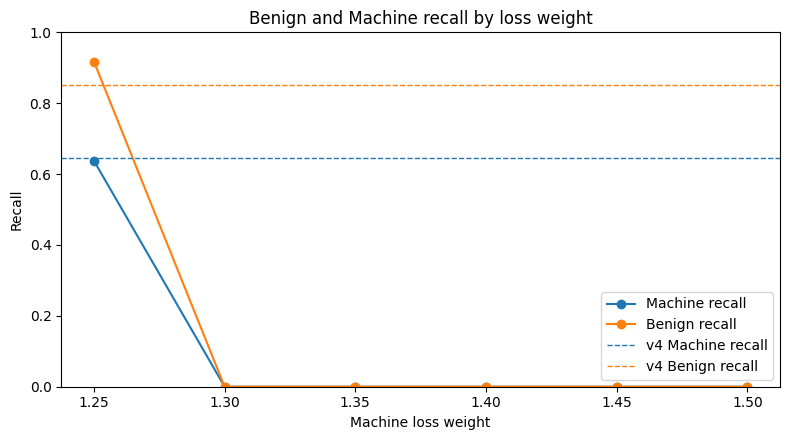

In [10]:
SWEEP = [
    ("v5.1", 1.25),
    ("v5.2", 1.30),
    ("v5.3", 1.35),
    ("v5.4", 1.40),
    ("v5.5", 1.45),
    ("v5.6", 1.50),
]

def class_counts(matrix, true_name, pred_name):
    labels = list(class_names)
    return int(matrix[labels.index(true_name), labels.index(pred_name)])

def score_split(model):
    probabilities = model.predict(test_ds, verbose=0)
    y_pred = np.argmax(probabilities, axis=1)
    y_true = np.concatenate([np.argmax(labels.numpy(), axis=1) for _, labels in test_ds])
    macro_precision, macro_recall, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    report = classification_report(
        y_true, y_pred, target_names=class_names, output_dict=True, zero_division=0
    )
    matrix = confusion_matrix(y_true, y_pred)
    return {
        "test_accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_precision": float(macro_precision),
        "macro_recall": float(macro_recall),
        "macro_f1": float(macro_f1),
        "classification_report": report,
        "confusion_matrix": matrix.tolist(),
    }

def result_row(version, weight, evaluation):
    report = evaluation["classification_report"]
    matrix = np.array(evaluation["confusion_matrix"])
    benign = report["Benign"]
    machine = report["Machine"]
    return {
        "version": version,
        "machine_loss_weight": weight,
        "accuracy": evaluation["test_accuracy"],
        "macro_f1": evaluation["macro_f1"],
        "benign_precision": benign["precision"],
        "benign_recall": benign["recall"],
        "benign_f1": benign["f1-score"],
        "machine_precision": machine["precision"],
        "machine_recall": machine["recall"],
        "machine_f1": machine["f1-score"],
        "benign_called_machine": class_counts(matrix, "Benign", "Machine"),
        "machine_called_benign": class_counts(matrix, "Machine", "Benign"),
    }

sweep_rows = [result_row("v4", 1.00, v4_metrics["evaluation"])]

for version, weight in SWEEP:
    print(f"\n===== {version}: Machine loss weight {weight:.2f} =====")
    MACHINE_LOSS_WEIGHT = weight
    tf.keras.utils.set_random_seed(SEED)
    model = build_v5()
    # New callback objects each run. Reusing them keeps the previous run's best
    # validation loss and then restores epoch-1 weights.
    sweep_callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1),
    ]
    history = model.fit(
        train_ds,
        validation_data=validation_ds,
        epochs=30,
        callbacks=sweep_callbacks,
        verbose=1,
    )
    evaluation = score_split(model)
    metrics = {
        "model_version": version,
        "created_utc": datetime.now(timezone.utc).isoformat(),
        "input_shape": [128, 128, 3],
        "class_names": class_names,
        "machine_loss_weight": weight,
        "evaluation": evaluation,
        "history": {key: [float(value) for value in values] for key, values in history.history.items()},
    }
    model_path = ARTIFACT_DIR / f"rf_intrusion_cnn_{version}.keras"
    metrics_path = ARTIFACT_DIR / f"rf_intrusion_cnn_{version}_metrics.json"
    model.save(model_path)
    metrics_path.write_text(json.dumps(metrics, indent=2))
    matrix = np.array(evaluation["confusion_matrix"])
    fig, ax = plt.subplots(figsize=(8, 6))
    ConfusionMatrixDisplay(matrix, display_labels=class_names).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(f"{version} — weight {weight:.2f}")
    ax.tick_params(axis="x", labelrotation=45)
    fig.tight_layout()
    fig.savefig(ARTIFACT_DIR / f"rf_intrusion_cnn_{version}_confusion_matrix.png", dpi=140)
    plt.close(fig)
    sweep_rows.append(result_row(version, weight, evaluation))
    print(
        f"{version}: accuracy {evaluation['test_accuracy']:.4f}, "
        f"macro F1 {evaluation['macro_f1']:.4f}, "
        f"Benign recall {evaluation['classification_report']['Benign']['recall']:.4f}, "
        f"Machine recall {evaluation['classification_report']['Machine']['recall']:.4f}"
    )
    del model

sweep_table = pd.DataFrame(sweep_rows)
v4_accuracy = float(sweep_table.loc[sweep_table["version"] == "v4", "accuracy"].iloc[0])
v4_macro_f1 = float(sweep_table.loc[sweep_table["version"] == "v4", "macro_f1"].iloc[0])
v4_benign_recall = float(sweep_table.loc[sweep_table["version"] == "v4", "benign_recall"].iloc[0])
v4_machine_recall = float(sweep_table.loc[sweep_table["version"] == "v4", "machine_recall"].iloc[0])
sweep_table["accuracy_vs_v4"] = sweep_table["accuracy"] - v4_accuracy
sweep_table["macro_f1_vs_v4"] = sweep_table["macro_f1"] - v4_macro_f1
sweep_table["benign_recall_vs_v4"] = sweep_table["benign_recall"] - v4_benign_recall
sweep_table["machine_recall_vs_v4"] = sweep_table["machine_recall"] - v4_machine_recall

sweep_csv = ARTIFACT_DIR / "v5_loss_weight_sweep.csv"
sweep_table.to_csv(sweep_csv, index=False)
print("Saved", sweep_csv)

display_columns = [
    "version", "machine_loss_weight", "accuracy", "macro_f1",
    "benign_recall", "benign_precision", "machine_recall", "machine_precision",
    "benign_called_machine", "machine_called_benign",
    "benign_recall_vs_v4", "machine_recall_vs_v4",
]
float_columns = [
    "machine_loss_weight", "accuracy", "macro_f1", "benign_recall", "benign_precision",
    "machine_recall", "machine_precision", "benign_recall_vs_v4", "machine_recall_vs_v4",
]
print("\nLoss-weight comparison against v4")
display(sweep_table[display_columns].style.format({column: "{:.4f}" for column in float_columns}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(8, 4.5))
candidates = sweep_table[sweep_table["version"] != "v4"]
ax.plot(candidates["machine_loss_weight"], candidates["machine_recall"], marker="o", label="Machine recall")
ax.plot(candidates["machine_loss_weight"], candidates["benign_recall"], marker="o", label="Benign recall")
ax.axhline(v4_machine_recall, color="C0", linestyle="--", linewidth=1, label="v4 Machine recall")
ax.axhline(v4_benign_recall, color="C1", linestyle="--", linewidth=1, label="v4 Benign recall")
ax.set_xlabel("Machine loss weight")
ax.set_ylabel("Recall")
ax.set_xticks(candidates["machine_loss_weight"])
ax.set_ylim(0, 1)
ax.legend()
ax.set_title("Benign and Machine recall by loss weight")
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "v5_loss_weight_sweep_recall.png", dpi=140)
plt.show()


## 7. Download the v5 artifact

Colab removes `/content` when the runtime stops. This cell zips the Keras model, metrics, and confusion matrix and downloads that zip to your computer.


In [ ]:
import shutil
from google.colab import files

archive = shutil.make_archive(str(WORKDIR / "rf_intrusion_cnn_v5_artifacts"), "zip", ARTIFACT_DIR)
print("Downloading", archive)
files.download(archive)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>